# Máximos direccionales agrupados con integridad dura

Nivel 4. Requisitos: objetivos cuadráticos convexos, restricciones de intervalo y la lección anterior de métodos equivalentes.

**Pregunta:** ¿Cómo cambia una decisión acoplada al valorar un máximo direccional compartido sin perder la igualdad dura ni la covarianza de unidades por fila?

Prerrequisito: [03-matching-published-methods](03-matching-published-methods.ipynb). Tiempo estimado de lectura y ejecución: 25 minutos.

## Objetivos

Un máximo agrupado valora la mayor desviación ponderada entre varias filas, en lugar de cobrar cada desviación por separado. Esa elección modifica la pregunta de ingeniería. Dos temperaturas que comparten un presupuesto de confort, por ejemplo, no necesariamente reciben la suma de dos penalizaciones independientes. Aquí se utiliza un caso matemático propio y pequeño para derivar también el óptimo a mano. La finalidad es comprender la implementación direccional real y comparar formulaciones exactas, sin incorporar mediciones temporales a ninguna de las campañas científicas completadas.

Al terminar podrá separar la igualdad dura de la caja penalizada, construir conversiones recíprocas de unidades, interpretar dimensiones y reconocer una comparación incompatible. También distinguirá un ejemplo exacto de la evidencia necesaria para afirmar una mejora computacional general. El experimento registrado rechazó ese criterio de mejora: una derivación clara y una solución pequeña correcta no revierten su resultado.

## Preparación

Conserve el núcleo del cuaderno en el entorno fijo de `notebooks/requirements.txt`, que mantiene softqp0.1.0. Instale el perfil sin cambios de nueve distribuciones `docs/teaching/coupled/requirements.txt` en otro entorno virtual externo Python3.12, creado desde un ejecutable CPython directo. Configure `SOFTQP_COUPLED_PYTHON` con su intérprete absoluto y `CAOS_TEMP_ROOT` con una carpeta temporal externa existente. En Windows se rechazan lanzadores intermediados de Store porque no garantizan la propiedad del árbol completo de procesos. El puente verifica huellas de la rueda pública SDK0.2, versiones exactas y sus propias fuentes; nunca instala dependencias durante la lección.

Cada llamada ejecuta realmente los métodos nativo, epígrafo compacto y separación direccional mediante `pipeline.coupled_lessons.run_comparison`. Ninguna celda define un solver alternativo.

```bash
python -m pip install softqp==0.1.0 numpy==2.5.4 scipy==1.18.1 matplotlib==3.11.2 osqp==1.1.3 daqp==0.10.3 elastiqp==0.2.0
```


In [1]:
# Concentrar rutas y versiones del núcleo evita repetir maquinaria en el razonamiento.
from pathlib import Path
import sys
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
root = Path.cwd().parents[2]
sys.path.insert(0, str(root / "data-pipeline"))
from pipeline.coupled_lessons import run_comparison, accepted_summary
def format_table(text):
    return Markdown(text.replace(".", ","))
states = {
    "accepted": "aceptado", "incompatible": "incompatible",
    "failed": "fallido", "accuracy-rejected": "precisión rechazada",
}

import importlib.metadata
for distribution in ['softqp', 'numpy', 'scipy', 'matplotlib', 'osqp', 'daqp', 'elastiqp']:
    print(distribution, importlib.metadata.version(distribution))


softqp 0.1.0
numpy 2.5.4
scipy 1.18.1
matplotlib 3.11.2
osqp 1.1.3
daqp 0.10.3
elastiqp 0.2.0


## Datos

Fuente de datos: entrada propia de dos variables, definida por el pipeline indicado. Las decisiones x1,x2 están en metros, P=I, q=(-3,2), y las filas son x1, x2 y x1+x2. Las primeras tienen intervalos blandos [-1,1]m; la última impone la igualdad dura x1+x2=0m. El objetivo combina una preferencia cuadrática de referencia con un máximo direccional adimensional. P tiene coeficientes unidad-objetivo/m² y q tiene unidad-objetivo/m; las escalas direccionales positivas se expresan en1/m.

La entrada `docs/teaching/coupled/accepted-summary.json` copia exactamente el resumen completo aceptado de forma independiente. Su lectura posterior examina inferencia publicada; no vuelve a generar observaciones ni reproduce su remuestreo. El análisis de los registros originales necesita el conjunto de datos separado citado al final.

Titular y licencia: Felipe Santibáñez-Leal es autor del pipeline y la entrada educativa (MIT); el resumen numérico aceptado y el conjunto de apoyo tienen licencia CC BY 4.0. Los perfiles de núcleo y proceso son declaraciones de dependencias, no datos observacionales. Los archivos locales corresponden a estas fuentes:

| Entrada / fuente | Archivo local | Referencia autorizada |
|---|---|---|
| QP propio / MIT | `data-pipeline/pipeline/coupled_lesson_worker.py` | https://github.com/fsantibanezleal/CAOS_SoftQP |
| Resumen aceptado / CC BY 4.0 | `docs/teaching/coupled/accepted-summary.json` | https://doi.org/10.5281/zenodo.23875194 |
| Perfil SDK público / software | `docs/teaching/coupled/requirements.txt` | https://pypi.org/project/softqp/0.2.0/ |


## Método

Defina r=x−clip(x,[-1,1]²) únicamente en el bloque blando. Con c−=(1,1.5) y c+=(u,1), utilice

$$t=\max(u[r_1]_+,[r_2]_+,[-r_1]_+,1.5[-r_2]_+),\qquad
J(x)=\tfrac12\lVert x\rVert^2-3x_1+2x_2+a t+\tfrac12 b t^2.$$

La igualdad se impone por separado; no debe incluirse en una identidad de convolución infimal sobre una caja totalmente blanda. Al escribir x=(s,−s), el término de referencia queda s²−5s. Para s≥1, el máximo es k(s−1), con k=max(u,1.5). La convexidad y la preferencia de referencia excluyen la rama exterior opuesta. Derivando en la rama positiva resulta

$$s^*=\max\left(1,\frac{5-a k+b k^2}{2+b k^2}\right).$$

Esta expresión es una comprobación interpretativa independiente para el caso propio, no un reemplazo del método. Comience con a=0.6,b=0,u=1 y examine decisiones, objetivo original y defecto de igualdad antes de cambiar un parámetro.

Fuente de la formulación direccional, derivación proximal y límites de las reformulaciones exactas: [estudio nativo](https://doi.org/10.5281/zenodo.23875071).

In [2]:
# Mostrar el óptimo físico real antes de modificar la política.
base = run_comparison(linear=0.6, quadratic=0, upper_scale=1)
display(format_table("| x1 (m) | x2 (m) | J |\n|---|---|---|\n" + "\n".join(
    f"| {r['x'][0]:.6f} | {r['x'][1]:.6f} | {r['objective']:.6f} |" for r in base["records"])))
print('x1 base (m)', f"{base['records'][0]['x'][0]:.6f}".replace(".", ","))


| x1 (m) | x2 (m) | J |
|---|---|---|
| 2,050000 | -2,050000 | -5,102500 |
| 2,050000 | -2,050000 | -5,102500 |
| 2,050000 | -2,050000 | -5,102500 |

x1 base (m) 2,050000


El método nativo y ambas reformulaciones recuperan aproximadamente (2,05;−2,05)m, con objetivo−5,1025 en las unidades declaradas. La desviación blanda distinta de cero es deliberada: la preferencia de referencia supera su precio marginal hasta alcanzar el óptimo. El error de la igualdad dura se mantiene al nivel del redondeo numérico. Domina la desviación inferior de la segunda fila, cuya escala1,5 supera la escala superior1 de la primera. La concordancia demuestra respuestas equivalentes para esta entrada; no proporciona evidencia temporal ni certificación de seguridad operativa.

Ahora elimine el precio lineal y use un precio cuadrático del máximo. Su costo marginal crece con la desviación. La separación direccional utilizada representa el máximo compartido lineal, por lo que la celda cuadrática debe conservar una incompatibilidad explícita. Sustituir su objetivo u omitirla fabricaría una concordancia aparente.

In [3]:
# Conservar la incompatibilidad cuadrática evita sustituir el objetivo de referencia.
quadratic = run_comparison(linear=0, quadratic=1, upper_scale=1)
labels = ['Nativo', 'Epígrafo compacto', 'Separación direccional']
headers = ['Método', 'Estado', 'x1 (m)', 'Objetivo']
rows = []
for name, record in zip(labels, quadratic["records"]):
    value = "-" if record["x"] is None else f"{record['x'][0]:.6f}"
    objective = "-" if record["objective"] is None else f"{record['objective']:.6f}"
    rows.append(f"| {name} | {states[record['state']]} | {value} | {objective} |")
display(format_table("| " + " | ".join(headers) + " |\n|---|---|---|---|\n" + "\n".join(rows)))

| Método | Estado | x1 (m) | Objetivo |
|---|---|---|---|
| Nativo | aceptado | 1,705882 | -5,058824 |
| Epígrafo compacto | aceptado | 1,705882 | -5,058824 |
| Separación direccional | incompatible | - | - |

Al cambiar solamente u a3, la dirección superior de la primera fila pasa a ser más cara que la dirección inferior de la segunda. La igualdad común acopla ambas decisiones: reducir x1 también modifica x2. Eso difiere de recortar coordenadas independientemente o reemplazar el máximo por una suma. Compare el nuevo óptimo con el inicial y con la fórmula. Los objetivos pertenecen a políticas distintas; su diferencia no es una brecha de precisión entre solvers ni una clasificación de desempeño.

In [4]:
# Cambiar una dirección conserva la misma igualdad dura acoplada.
directional = run_comparison(linear=0.6, quadratic=0, upper_scale=3)
display(format_table("| x1 (m) | x2 (m) | t |\n|---|---|---|\n" + "\n".join(
    f"| {r['x'][0]:.6f} | {r['x'][1]:.6f} | {r['peak']:.6f} |" for r in directional["records"])))

| x1 (m) | x2 (m) | t |
|---|---|---|
| 1,600000 | -1,600000 | 1,800000 |
| 1,600000 | -1,600000 | 1,800000 |
| 1,600000 | -1,600000 | 1,800000 |

## Comparación

El epígrafo compacto introduce una variable compartida para el máximo. La separación agrega filas de desigualdad direccionales y conserva la cantidad original de decisiones. El método nativo mantiene las tres filas de intervalo originales. Son alternativas exactas donde se cumplen sus supuestos. La figura cuenta variables primales y filas realmente ensambladas sobre la misma entrada base; no contiene un eje de tiempo. Una dimensión menor puede reducir ciertas operaciones y aun así perder en conjunto por proyección, ensamblado, movimiento de memoria o convergencia.

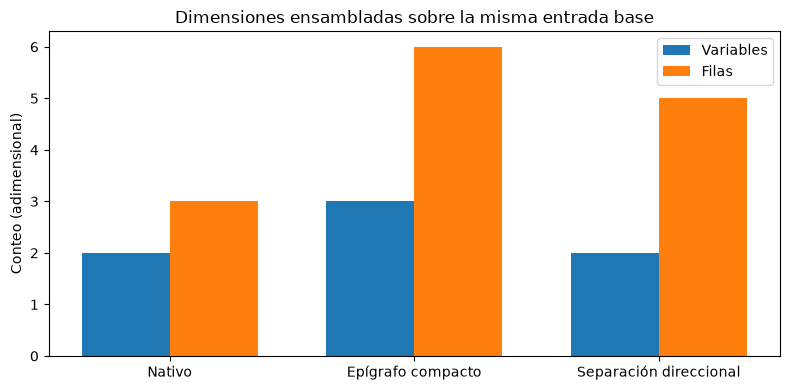

In [5]:
# Contar dimensiones reales sin presentarlas como evidencia temporal.
fig, ax = plt.subplots(figsize=(8, 4))
positions = list(range(3))
variables = [r["dimensions"]["variables"] for r in base["records"]]
constraints = [r["dimensions"]["rows"] for r in base["records"]]
ax.bar([p - 0.18 for p in positions], variables, width=0.36, label='Variables')
ax.bar([p + 0.18 for p in positions], constraints, width=0.36, label='Filas')
ax.set(xticks=positions, xticklabels=labels, ylabel='Conteo (adimensional)',
       title='Dimensiones ensambladas sobre la misma entrada base')
ax.legend()
fig.tight_layout()
plt.show()

La formulación nativa utiliza dos variables primales y tres filas; el epígrafo compacto tiene tres variables y seis filas; la separación direccional mantiene dos variables y agrega cinco filas en total. Los conteos corresponden a este problema exacto de dos decisiones, incluida su igualdad dura. No contabilizan cada memoria interna ni prueban una ventaja temporal asintótica. El ejemplo cuadrático muestra por qué el gráfico de dimensiones necesita también estados de compatibilidad: la ausencia de representación matemática nunca debe parecer una solución exitosa especialmente pequeña.

## Evidencia

Cambiar unidades de una fila modifica solamente la representación cuando cambian todas las cantidades relacionadas. Sea D=diag(d,d,1): sustituya A,l,u por DA,Dl,Du y divida ambas escalas direccionales por d en las filas blandas. Entonces r′=Dsoft r y cada desviación direccional ponderada permanece idéntica. El máximo adimensional, la decisión física y el objetivo original son invariantes. La igualdad conserva aquí su coordenada inicial. Ejecute por separado conversiones d=0.01 y100 mediante los métodos reales: son soluciones educativas nuevas, no miembros adicionales de la población científica registrada.

In [6]:
# Ejecutar la conversión recíproca pequeña en un proceso real independiente.
small_rows = run_comparison(linear=0.6, quadratic=0, upper_scale=3, row_scale=0.01)
display(format_table("| d | x1 (m) | J |\n|---|---|---|\n" +
    f"| 0.01 | {small_rows['records'][0]['x'][0]:.6f} | {small_rows['records'][0]['objective']:.6f} |"))

| d | x1 (m) | J |
|---|---|---|
| 0,01 | 1,600000 | -4,360000 |

La segunda conversión mantiene la política física y utiliza la escala opuesta. Compare x1 recuperado por los tres métodos reales: cambiar la decisión contradiría esta transformación de coordenadas.

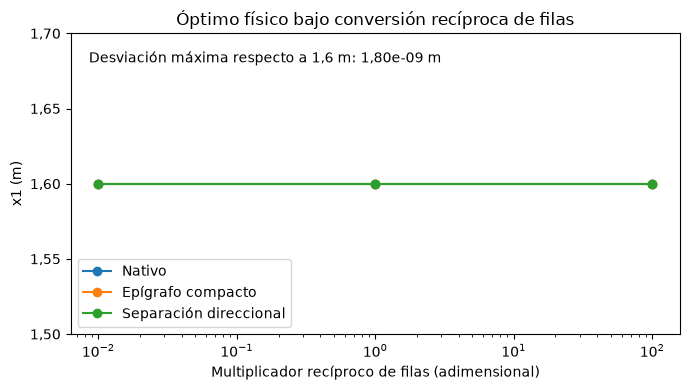

In [7]:
# Repetir la escala opuesta distingue invariancia física de una sola solución correcta.
large_rows = run_comparison(linear=0.6, quadratic=0, upper_scale=3, row_scale=100)
fig, ax = plt.subplots(figsize=(7, 4))
for i, label in enumerate(labels):
    values = [r["records"][i]["x"][0] for r in (small_rows, directional, large_rows)]
    ax.plot([0.01, 1, 100], values, marker="o", label=label)
ax.set(xscale="log", xlabel='Multiplicador recíproco de filas (adimensional)',
       ylabel="x1 (m)", title='Óptimo físico bajo conversión recíproca de filas')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, pos: f"{value:.2f}".replace(".", ",")))
ax.set_ylim(1.5, 1.7)
ax.set_yticks([1.5, 1.55, 1.6, 1.65, 1.7])
maximum_error = max(abs(record["x"][0] - 1.6)
                    for result in (small_rows, directional, large_rows) for record in result["records"])
error_text = f"{maximum_error:.2e}".replace(".", ",")
ax.text(0.03, 0.94, 'Desviación máxima respecto a 1,6 m: ' + error_text + " m", transform=ax.transAxes, va="top")
ax.legend(loc="lower left")
fig.tight_layout()
plt.show()

Con ambas conversiones recíprocas, el valor físico recuperado de x1 permanece igual al de la política direccional sin convertir. El eje horizontal representa el multiplicador positivo de las coordenadas por fila; no es tiempo transcurrido ni una nueva unidad de decisión. El solver puede recorrer otra trayectoria numérica al escalar: la invariancia se refiere a la respuesta matemática original dentro de las comprobaciones declaradas. Omitir escalas inversas cambiaría el precio, no su representación. Como contraejemplo deliberado, aumentar nuevamente u a4 altera la política y desplaza el óptimo; ninguna afirmación de covarianza corresponde a ese cambio.

El intervalo físico vertical común va de1,5 a1,7m, por lo que las tres curvas se superponen. La desviación máxima anotada frente a la respuesta analítica de1,6m cuantifica redondeo numérico; no representa una separación física significativa entre métodos.

In [8]:
# Alterar deliberadamente el precio sirve como control de otra política.
changed_policy = run_comparison(linear=0.6, quadratic=0, upper_scale=4)
display(format_table("| u | x1 (m) |\n|---|---|\n" +
    f"| 4 | {changed_policy['records'][0]['x'][0]:.6f} |"))

| u | x1 (m) |
|---|---|
| 4 | 1,300000 |

La comparación registrada completa responde otra pregunta de evidencia. El resumen aceptado conserva144 instancias reservadas, seis grupos de semilla y nueve pares fallidos conforme a la regla fijada. La tabla lee una vez ese resultado exacto revisado. La puntuación combina reducción relativa pareada y una regla para fallos; no puede convertirse en un multiplicador universal de ralentización. Su incertidumbre y sus fallos conservados forman parte de la conclusión, junto con el incumplimiento de la mejora exigida. Esta lección no remuestrea, cambia umbrales ni selecciona casos favorables.

In [9]:
# Leer una vez inferencia completa aceptada no reproduce los registros originales.
evidence = accepted_summary()["primary"]
head = 'Casos reservados | Grupos de semilla | Pares fallidos | Reducción (%) | Intervalo95% (%)'
lower, upper = evidence["confidence_interval"]
body = (f"| {evidence['denominator']} | {evidence['seed_clusters']} | {evidence['failed_pairs']} | "
        f"{100*evidence['estimate']:.4f} | [{100*lower:.4f}, {100*upper:.4f}] |")
display(format_table("| " + head + " |\n|---|---|---|---|---|\n" + body))

| Casos reservados | Grupos de semilla | Pares fallidos | Reducción (%) | Intervalo95% (%) |
|---|---|---|---|---|
| 144 | 6 | 9 | -212,4499 | [-225,3366, -192,8738] |

## Resultados

**Respuesta:** Un precio lineal compartido0,6 produce x1≈2,050000m en el caso base; cambiar la escala superior inicial a3 produce x1≈1,6m mientras conserva x1+x2≈0m. Las conversiones recíprocas0,01 y100 mantienen esa última decisión física. Son números calculados mediante llamadas reales anteriores. La política cuadrática sigue admitida por los métodos nativo y epígrafo, y conserva incompatibilidad explícita con esta referencia por separación.

El resultado científico es negativo: aproximadamente−212,45%, con intervalo del95% por semilla aproximadamente[−225,34%;−192,87%], incluidos nueve pares fallidos. No establece la ganancia registrada del10%. La concordancia exacta y la reducción de filas del ejemplo explican representación, no una ventaja general.

Límites: se trata de un modelo educativo convexo con métrica fija y dos variables. Se suponen grupos direccionales disjuntos positivos y la configuración indicada. No contiene certificación de control, política entrenada, planta medida, conclusión temporal universal ni prueba de prioridad. Las comprobaciones de procesos y precisión mejoran reproducibilidad, pero no aportan valor empírico ausente.

## Resumen

La decisión de ingeniería es el máximo direccional valorado; su representación numérica es otra decisión. Ahora puede modificar a o b, anticipar analíticamente el óptimo de la rama y solicitar una respuesta comprobada a los métodos reales. Al adaptar el ejemplo conserve la fila dura, las unidades originales y los estados incompatibles.

Ejercicios: encuentre primero un precio lineal que ubique el óptimo exactamente en la frontera de la caja y explique la condición marginal. Después reduzca la escala superior por debajo de1,5 y explique por qué sigue dominando la dirección inferior. Finalmente intente convertir coordenadas sin escalas recíprocas, derive antes el objetivo modificado y explique por qué llamar al resultado un fallo de unidades confundiría una política diferente con otra representación. Ninguna exploración modifica el estudio registrado.

## Referencias

- Estudio direccional, derivación nativa y resultado negativo completo: https://doi.org/10.5281/zenodo.23875071
- Conjunto registrado completo de apoyo: https://doi.org/10.5281/zenodo.23875194
- Proyección generalizada publicada: https://arxiv.org/abs/2610.35631
- ADMM y supuestos de OSQP: https://osqp.org/docs/solver/
- Implementación pública: https://pypi.org/project/softqp/0.2.0/

El estudio sustenta las derivaciones y el experimento informados, sin establecer prioridad ni superioridad.